<a href="https://colab.research.google.com/github/BuvanAlfarezy/BuvanAlfarezy_Test1_KlasifikasiXGBoost/blob/main/BuvanAlfarezy_Test1_KlasifikasiXGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install xgboost streamlit joblib

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")

uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Tidak ditemukan file CSV. Ekstrak ZIP dari Kaggle dan upload file .csv.")

# Jika mengunggah beberapa CSV, ubah CSV_FILE secara manual.
CSV_FILE = csv_files[0]
df = pd.read_csv(CSV_FILE)
df.columns = [str(col).strip() for col in df.columns]
df = df.drop_duplicates().reset_index(drop=True)

print(f"File dibaca: {CSV_FILE}")
print(f"Ukuran dataset: {df.shape[0]:,} baris × {df.shape[1]} kolom")
display(df.head())

Saving kolkata_weather_jan_june_2026.csv to kolkata_weather_jan_june_2026.csv
File dibaca: kolkata_weather_jan_june_2026.csv
Ukuran dataset: 1,827 baris × 17 kolom


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [3]:
print("Daftar kolom:")
print(df.columns.tolist())

print("\\nInformasi tipe data dan nilai non-null:")
df.info()

print("\\nJumlah missing value per kolom:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("\\nRingkasan statistik numerik:")
display(df.describe(include=[np.number]).T)

print("\\nRingkasan kolom kategorikal:")
display(df.describe(include=["object", "category", "bool"]).T)

Daftar kolom:
['time', 'weather_code', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunrise', 'sunset', 'sunshine_duration', 'city', 'latitude', 'longitude']
\nInformasi tipe data dan nilai non-null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   object 
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitatio

,Missing Values
time,0
weather_code,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
wind_speed_10m_max,0
wind_gusts_10m_max,0


\nRingkasan statistik numerik:


,count,mean,std,min,25%,50%,75%,max
weather_code,1827.0,34.143952,2.899722e+01,0.0000,3.0000,51.0000,63.0000,65.0000
temperature_2m_mean,1827.0,26.264860,4.050220e+00,15.0000,23.4000,27.4000,29.1000,35.2000
temperature_2m_max,1827.0,31.099234,3.924558e+00,19.6000,28.7000,31.3000,33.3000,43.9000
temperature_2m_min,1827.0,22.477066,4.847343e+00,10.2000,18.6000,24.6000,26.2000,30.6000
precipitation_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
rain_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
precipitation_hours,1827.0,4.952928,6.275264e+00,0.0000,0.0000,2.0000,9.0000,24.0000
wind_speed_10m_max,1827.0,13.782157,5.106847e+00,4.5000,10.0000,12.6000,16.6000,44.0000
wind_gusts_10m_max,1827.0,30.756596,9.081119e+00,11.5000,24.1000,29.5000,36.0000,83.9000
wind_direction_10m_dominant,1827.0,192.212917,1.001658e+02,0.0000,135.0000,188.0000,258.0000,360.0000


\nRingkasan kolom kategorikal:


,count,unique,top,freq
time,1827,1827,2026-06-30,1
sunrise,1827,1827,2026-06-30T04:55,1
sunset,1827,1827,2026-06-30T18:25,1
city,1827,1,Kolkata,1827


Tidak ada missing value pada dataset mentah.


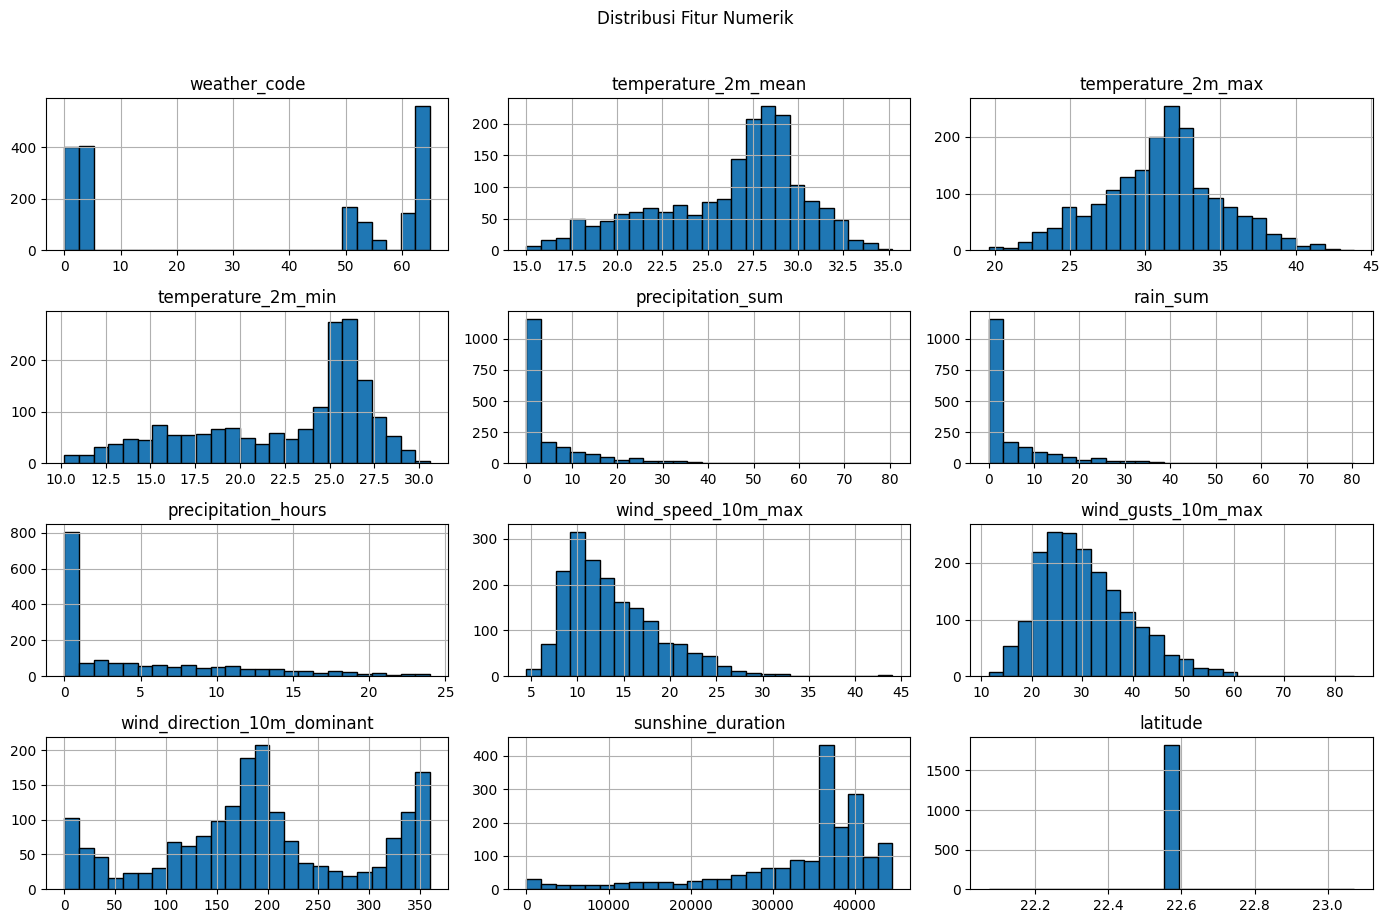

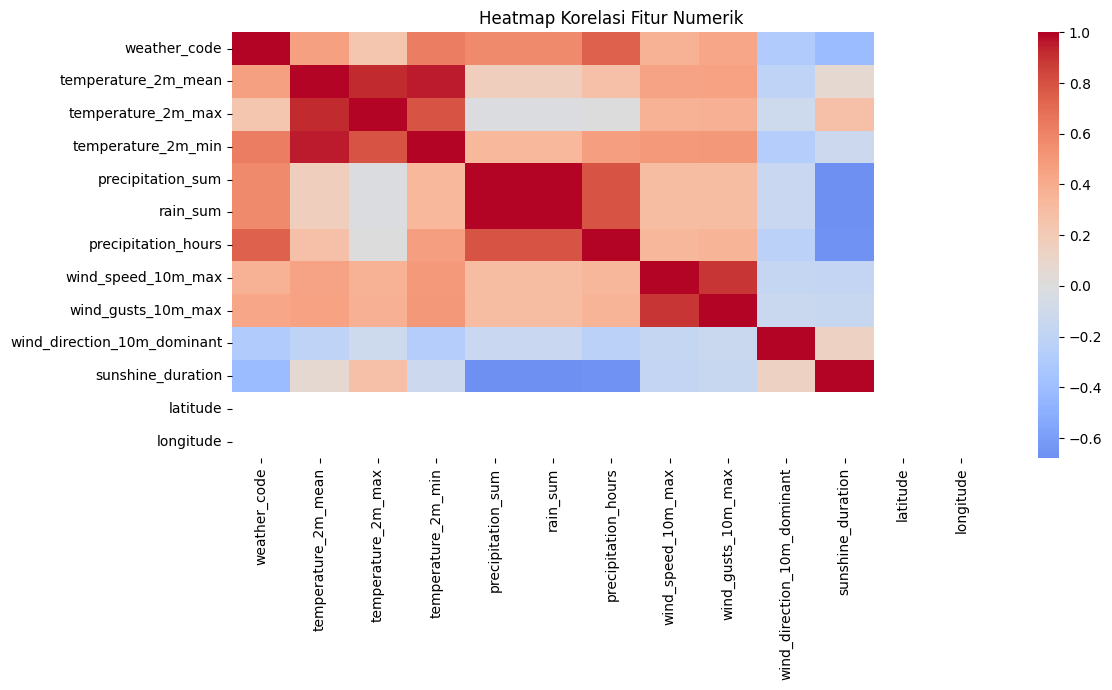

In [4]:
# Missing value per kolom
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    plt.figure(figsize=(10, 4))
    missing.plot(kind="bar")
    plt.title("Jumlah Missing Value per Kolom")
    plt.ylabel("Jumlah")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada missing value pada dataset mentah.")

# Histogram fitur numerik (maksimal 12 kolom agar grafik tetap rapi)
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
if numeric_columns:
    df[numeric_columns[:12]].hist(figsize=(14, 9), bins=25, edgecolor="black")
    plt.suptitle("Distribusi Fitur Numerik", y=1.02)
    plt.tight_layout()
    plt.show()

# Heatmap korelasi fitur numerik
if len(numeric_columns) >= 2:
    plt.figure(figsize=(12, 7))
    sns.heatmap(df[numeric_columns].corr(numeric_only=True), cmap="coolwarm", center=0)
    plt.title("Heatmap Korelasi Fitur Numerik")
    plt.tight_layout()
    plt.show()

In [5]:
def normalize_name(name):
    """Normalisasi nama kolom: hanya huruf dan angka, huruf kecil."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

normalized_columns = {col: normalize_name(col) for col in df.columns}

# Kandidat target kategorikal yang diprioritaskan.
preferred_target_names = [
    "weathercondition", "conditiontext", "conditions", "condition", "weather",
    "raincategory", "rainfallcategory", "rainstatus", "rain", "target", "label", "class"
]

def find_existing_categorical_target(frame):
    for wanted in preferred_target_names:
        for col in frame.columns:
            if normalized_columns[col] != wanted:
                continue
            series = frame[col]
            unique_count = series.dropna().nunique()
            is_categorical = (
                pd.api.types.is_object_dtype(series)
                or isinstance(series.dtype, pd.CategoricalDtype)
                or pd.api.types.is_bool_dtype(series)
                or unique_count <= 15
            )
            if unique_count >= 2 and is_categorical:
                return col
    return None

TARGET_SOURCE = find_existing_categorical_target(df)
TARGET_IS_DERIVED = False
TARGET_NAME = None

if TARGET_SOURCE is not None:
    print(f"Target kategorikal ditemukan: {TARGET_SOURCE!r}")
    y_source = df[TARGET_SOURCE].copy()
    TARGET_NAME = TARGET_SOURCE
else:
    # Cari kolom curah hujan numerik jika tidak ditemukan label kategorikal.
    rain_exact_names = [
        "precipitationmm", "precipmm", "rainfallmm", "rainmm",
        "precipitation", "rainfall", "precip", "rainamount", "rain"
    ]
    rain_col = None
    for wanted in rain_exact_names:
        for col in df.columns:
            name = normalized_columns[col]
            if name == wanted and not any(token in name for token in ["prob", "chance", "percent"]):
                candidate = pd.to_numeric(df[col], errors="coerce")
                if candidate.notna().sum() > 0 and candidate.nunique(dropna=True) >= 2:
                    rain_col = col
                    break
        if rain_col is not None:
            break
    if rain_col is None:
        # Cadangan: nama mengandung rain/precip, tetapi bukan probabilitas.
        for col in df.columns:
            name = normalized_columns[col]
            if any(token in name for token in ["rainfall", "precipitation", "precip", "rainamount", "rainmm"]):
                if any(token in name for token in ["prob", "chance", "percent", "cover"]):
                    continue
                candidate = pd.to_numeric(df[col], errors="coerce")
                if candidate.notna().sum() > 0 and candidate.nunique(dropna=True) >= 2:
                    rain_col = col
                    break

    if rain_col is None:
        raise ValueError(
            "Target kategori tidak ditemukan dan kolom curah hujan numerik juga tidak ditemukan. "
            f"Kolom yang tersedia: {df.columns.tolist()}. Ubah TARGET_SOURCE secara manual sesuai CSV."
        )

    rain_values = pd.to_numeric(df[rain_col], errors="coerce")
    y_source = pd.Series(index=df.index, dtype="object")
    y_source.loc[rain_values <= 0] = "Tidak hujan"
    y_source.loc[(rain_values > 0) & (rain_values <= 15.5)] = "Hujan ringan"
    y_source.loc[rain_values > 15.5] = "Hujan sedang/lebat"

    # Jika kategori intensitas terlalu jarang, gabungkan menjadi hujan/tidak hujan.
    class_counts = y_source.value_counts(dropna=True)
    if (class_counts < 2).any():
        binary_target = pd.Series(index=df.index, dtype="object")
        binary_target.loc[rain_values <= 0] = "Tidak hujan"
        binary_target.loc[rain_values > 0] = "Hujan"
        if binary_target.dropna().nunique() >= 2 and (binary_target.value_counts() >= 2).all():
            y_source = binary_target
            TARGET_NAME = "Status hujan (dibentuk dari curah hujan)"
        else:
            TARGET_NAME = "Kategori hujan (dibentuk dari curah hujan)"
    else:
        TARGET_NAME = "Kategori hujan (dibentuk dari curah hujan)"

    TARGET_SOURCE = rain_col
    TARGET_IS_DERIVED = True
    print(f"Tidak ada label kategori yang cocok. Target dibentuk dari kolom curah hujan: {rain_col!r}")

# Buang baris tanpa label yang valid.
valid_target = y_source.notna() & y_source.astype(str).str.strip().ne("")
y = y_source.loc[valid_target].astype(str).str.strip()

# Bentuk fitur dari kolom selain target.
if TARGET_IS_DERIVED:
    # Penting: buang kolom curah hujan sumber beserta kolom lain yang berpotensi mengungkap target secara langsung.
    leak_cols = [
        col for col in df.columns
        if any(token in normalized_columns[col] for token in ["rain", "precip"])
    ]
    feature_df = df.drop(columns=leak_cols, errors="ignore").copy()
else:
    feature_df = df.drop(columns=[TARGET_SOURCE], errors="ignore").copy()
    target_norm = normalized_columns[TARGET_SOURCE]
    if any(token in target_norm for token in ["condition", "weather", "rain", "target", "label", "class"]):
        # Hilangkan kolom teks yang berisiko menjadi salinan/representasi langsung dari target.
        proxy_cols = []
        for col in feature_df.columns:
            name = normalized_columns[col]
            if col == TARGET_SOURCE:
                continue
            if any(token in name for token in ["description", "weathercondition", "conditiontext", "raincategory", "rainstatus"]):
                proxy_cols.append(col)
        feature_df = feature_df.drop(columns=proxy_cols, errors="ignore")

# Deteksi kolom tanggal/waktu dan buat fitur kalender.
date_col = None
date_values = None
for col in feature_df.columns:
    name = normalized_columns[col]
    if name in {"date", "datetime", "timestamp", "observationdate", "weatherdate"} or "datetime" in name or name.endswith("date"):
        parsed = pd.to_datetime(feature_df[col], errors="coerce")
        if parsed.notna().mean() >= 0.70:
            date_col = col
            date_values = parsed
            break

if date_col is not None:
    feature_df["date_year"] = date_values.dt.year
    feature_df["date_month"] = date_values.dt.month
    feature_df["date_day"] = date_values.dt.day
    feature_df["date_dayofweek"] = date_values.dt.dayofweek
    feature_df["date_dayofyear_sin"] = np.sin(2 * np.pi * date_values.dt.dayofyear / 365.25)
    feature_df["date_dayofyear_cos"] = np.cos(2 * np.pi * date_values.dt.dayofyear / 365.25)
    feature_df = feature_df.drop(columns=[date_col], errors="ignore")
    print(f"Fitur kalender dibuat dari kolom tanggal: {date_col!r}")
else:
    print("Kolom tanggal tidak terdeteksi; pembagian data akan memakai stratified random split.")

# Hapus kolom ID/unnamed yang tidak informatif.
remove_cols = []
for col in feature_df.columns:
    name = normalized_columns.get(col, normalize_name(col))
    if name.startswith("unnamed") or name in {"id", "index", "rowid", "uuid", "recordid"}:
        remove_cols.append(col)
feature_df = feature_df.drop(columns=remove_cols, errors="ignore")

# Ubah kolom string yang sebenarnya berisi angka menjadi numeric jika mayoritas nilainya bisa dikonversi.
for col in feature_df.columns:
    if pd.api.types.is_object_dtype(feature_df[col]) or pd.api.types.is_string_dtype(feature_df[col]):
        converted = pd.to_numeric(feature_df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")
        non_missing_original = feature_df[col].notna().sum()
        if non_missing_original > 0 and converted.notna().sum() / non_missing_original >= 0.80:
            feature_df[col] = converted

# Buang kolom teks ber-cardinality tinggi serta kolom konstan.
for col in list(feature_df.columns):
    series = feature_df[col]
    unique_count = series.nunique(dropna=True)
    if unique_count <= 1:
        feature_df = feature_df.drop(columns=[col])
        continue
    if not (pd.api.types.is_numeric_dtype(series) or pd.api.types.is_bool_dtype(series)):
        max_unique_allowed = min(50, max(20, int(0.10 * len(feature_df))))
        if unique_count > max_unique_allowed:
            feature_df = feature_df.drop(columns=[col])

# Sinkronkan baris X dan y, lalu bersihkan nilai tak hingga.
X = feature_df.loc[y.index].copy()
X = X.replace([np.inf, -np.inf], np.nan)

# Hapus fitur yang seluruh nilainya kosong.
all_missing_cols = X.columns[X.isna().all()].tolist()
if all_missing_cols:
    X = X.drop(columns=all_missing_cols)

# Pastikan target memiliki cukup kelas.
counts = y.value_counts()
rare_classes = counts[counts < 2].index.tolist()
if rare_classes:
    print("Kelas target dengan kurang dari 2 baris dihapus karena tidak dapat dibagi ke train dan test:", rare_classes)
    keep_rows = ~y.isin(rare_classes)
    X = X.loc[keep_rows]
    y = y.loc[keep_rows]

if y.nunique() < 2:
    raise ValueError("Target hanya memiliki satu kelas setelah pembersihan. Klasifikasi membutuhkan minimal dua kelas.")
if X.shape[1] == 0:
    raise ValueError("Tidak ada fitur yang tersisa. Periksa kembali nama kolom dan aturan pemilihan fitur.")

# Rapikan tipe data fitur kategorikal agar bisa diproses oleh OneHotEncoder.
for col in X.columns:
    if not (pd.api.types.is_numeric_dtype(X[col]) or pd.api.types.is_bool_dtype(X[col])):
        X[col] = X[col].map(lambda value: str(value) if pd.notna(value) else np.nan)

# Tanggal untuk pembagian kronologis; selaraskan dengan baris yang dipakai.
if date_values is not None:
    date_for_split = date_values.loc[X.index]
else:
    date_for_split = None

print("\\n===== RINGKASAN SETELAH PRA-PEMROSESAN =====")
print("Nama target:", TARGET_NAME)
print("Kolom target sumber:", TARGET_SOURCE)
print("Target dibentuk dari curah hujan:", TARGET_IS_DERIVED)
print("Jumlah data siap model:", len(X))
print("Jumlah fitur:", X.shape[1])
print("Kolom fitur:", X.columns.tolist())
print("Jumlah kelas target:", y.nunique())
display(y.value_counts().rename_axis("Kelas").to_frame("Jumlah"))

Tidak ada label kategori yang cocok. Target dibentuk dari kolom curah hujan: 'precipitation_sum'
Kolom tanggal tidak terdeteksi; pembagian data akan memakai stratified random split.
\n===== RINGKASAN SETELAH PRA-PEMROSESAN =====
Nama target: Kategori hujan (dibentuk dari curah hujan)
Kolom target sumber: precipitation_sum
Target dibentuk dari curah hujan: True
Jumlah data siap model: 1827
Jumlah fitur: 8
Kolom fitur: ['weather_code', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration']
Jumlah kelas target: 3


,Jumlah
Kelas,
Tidak hujan,806
Hujan ringan,804
Hujan sedang/lebat,217


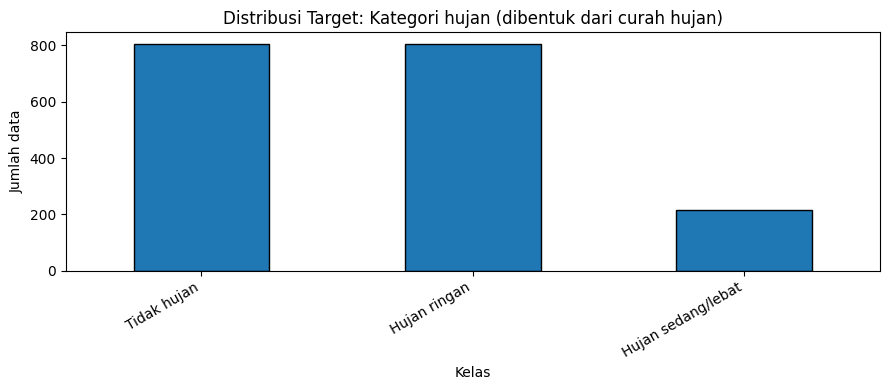

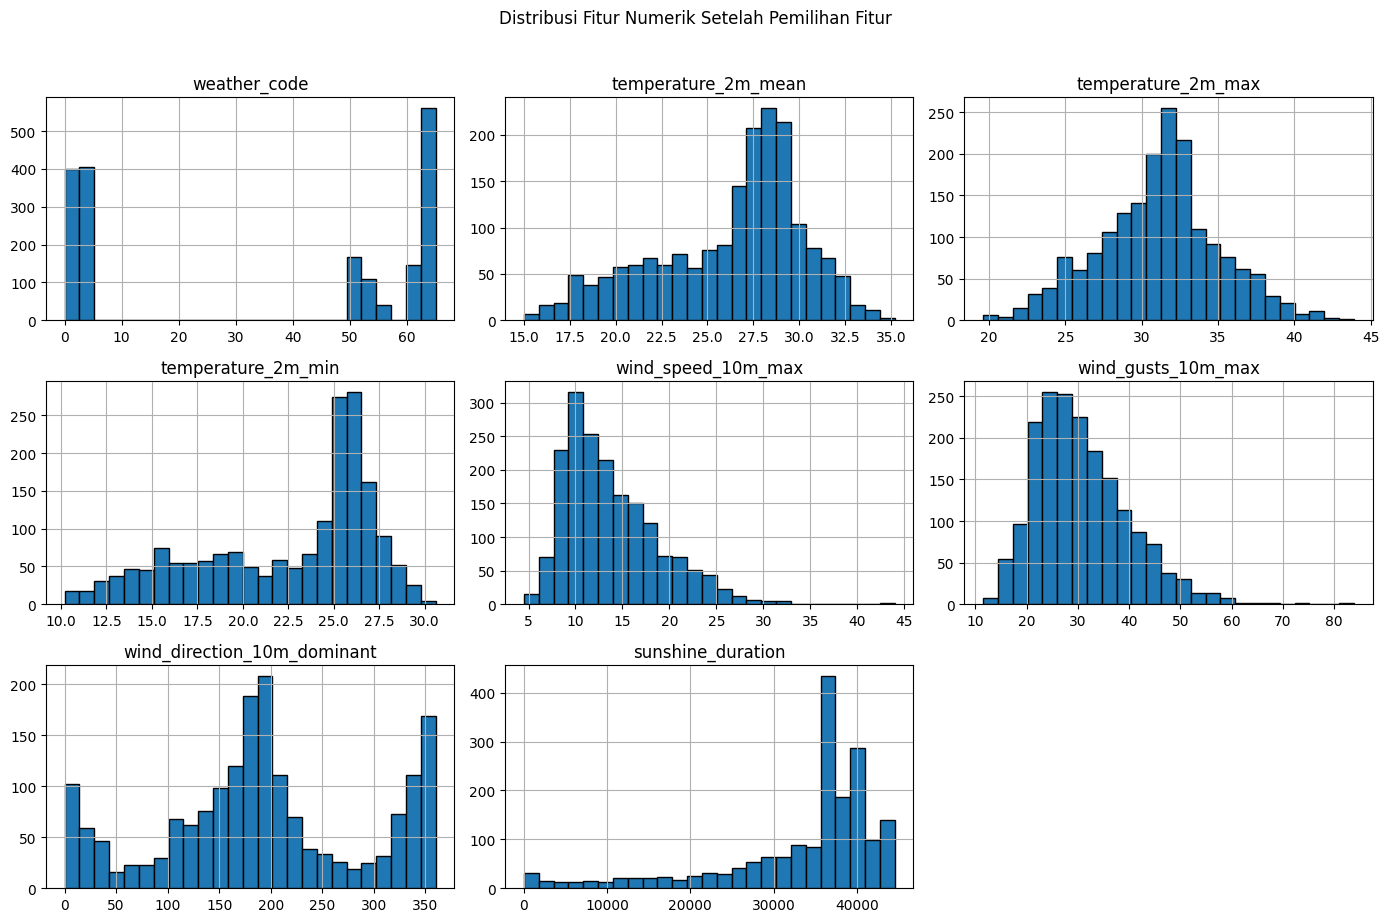

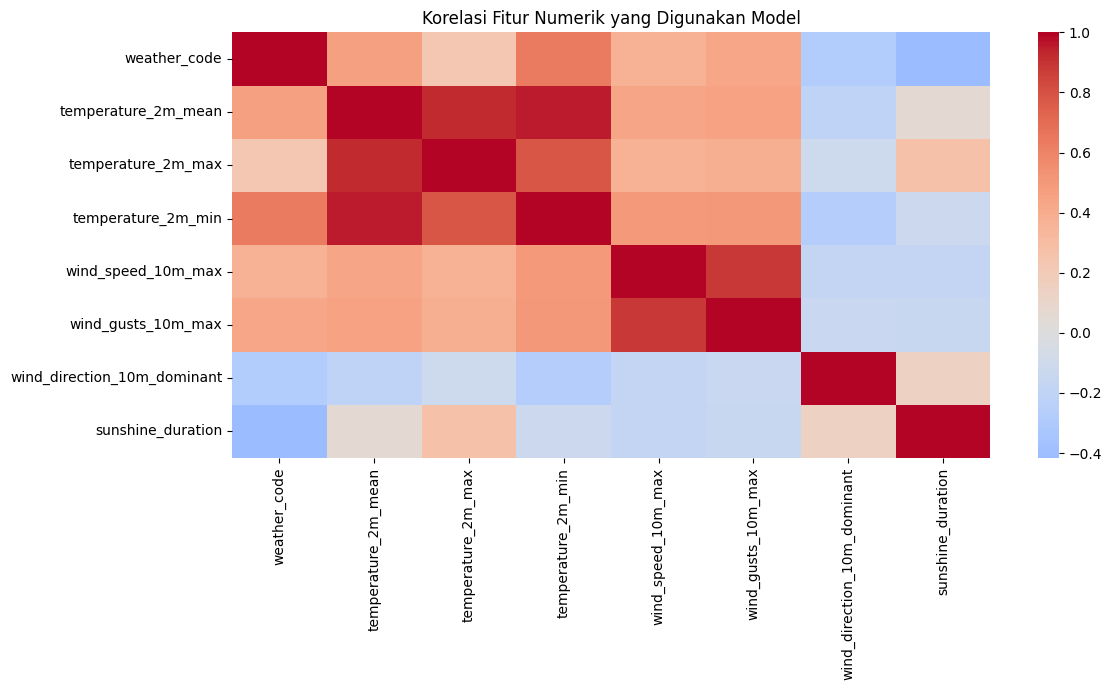

Missing value fitur setelah pemilihan kolom:


,Missing Values
weather_code,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
wind_speed_10m_max,0
wind_gusts_10m_max,0
wind_direction_10m_dominant,0
sunshine_duration,0


In [6]:
# Proporsi kelas target
plt.figure(figsize=(9, 4))
y.value_counts().plot(kind="bar", edgecolor="black")
plt.title(f"Distribusi Target: {TARGET_NAME}")
plt.xlabel("Kelas")
plt.ylabel("Jumlah data")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Distribusi beberapa fitur numerik yang sudah dipilih
eda_numeric = X.select_dtypes(include=np.number).columns.tolist()
if eda_numeric:
    X[eda_numeric[:12]].hist(figsize=(14, 9), bins=25, edgecolor="black")
    plt.suptitle("Distribusi Fitur Numerik Setelah Pemilihan Fitur", y=1.02)
    plt.tight_layout()
    plt.show()

if len(eda_numeric) >= 2:
    plt.figure(figsize=(12, 7))
    sns.heatmap(X[eda_numeric[:20]].corr(numeric_only=True), cmap="coolwarm", center=0)
    plt.title("Korelasi Fitur Numerik yang Digunakan Model")
    plt.tight_layout()
    plt.show()

print("Missing value fitur setelah pemilihan kolom:")
display(X.isna().sum().sort_values(ascending=False).to_frame("Missing Values"))

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from xgboost import XGBClassifier

TEST_SIZE = 0.20
RANDOM_STATE = 42
split_strategy = "stratified random split"

train_idx = None
test_idx = None
if date_for_split is not None:
    sorted_idx = date_for_split.sort_values(na_position="last").index
    cut = int(len(sorted_idx) * (1 - TEST_SIZE))
    candidate_train_idx = sorted_idx[:cut]
    candidate_test_idx = sorted_idx[cut:]
    if len(candidate_train_idx) >= 2 and len(candidate_test_idx) >= 1:
        train_labels = set(y.loc[candidate_train_idx])
        test_labels = set(y.loc[candidate_test_idx])
        if len(train_labels) >= 2 and len(test_labels - train_labels) == 0:
            train_idx, test_idx = candidate_train_idx, candidate_test_idx
            split_strategy = "chronological 80:20 split"
        else:
            print("Pembagian kronologis dibatalkan: ada kelas di data uji yang tidak dijumpai di data latih.")

if train_idx is not None:
    X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
    y_train_raw, y_test_raw = y.loc[train_idx].copy(), y.loc[test_idx].copy()
else:
    stratify_labels = y if (y.value_counts().min() >= 2 and int(np.ceil(TEST_SIZE * len(y))) >= y.nunique()) else None
    X_train, X_test, y_train_raw, y_test_raw = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=stratify_labels
    )
    split_strategy = "stratified random split" if stratify_labels is not None else "random split (tanpa stratifikasi)"

print("Strategi split:", split_strategy)
print(f"Jumlah training: {len(X_train):,} ({len(X_train)/len(X):.1%})")
print(f"Jumlah testing : {len(X_test):,} ({len(X_test)/len(X):.1%})")
print("Distribusi kelas training:")
display(y_train_raw.value_counts().rename_axis("Kelas").to_frame("Jumlah"))
print("Distribusi kelas testing:")
display(y_test_raw.value_counts().rename_axis("Kelas").to_frame("Jumlah"))

# LabelEncoder hanya di-fit pada y training untuk mempertahankan mapping kelas yang benar.
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_test = label_encoder.transform(y_test_raw)
class_names = label_encoder.classes_.tolist()

numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [col for col in X_train.columns if col not in numeric_cols]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_cols:
    transformers.append(("num", numeric_pipeline, numeric_cols))
if categorical_cols:
    transformers.append(("cat", categorical_pipeline, categorical_cols))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=RANDOM_STATE,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
print("Model XGBoost berhasil dilatih.")

Strategi split: stratified random split
Jumlah training: 1,461 (80.0%)
Jumlah testing : 366 (20.0%)
Distribusi kelas training:


,Jumlah
Kelas,
Tidak hujan,645
Hujan ringan,643
Hujan sedang/lebat,173


Distribusi kelas testing:


,Jumlah
Kelas,
Tidak hujan,161
Hujan ringan,161
Hujan sedang/lebat,44


Model XGBoost berhasil dilatih.


===== METRIK EVALUASI =====


,Metrik,Nilai
0,Accuracy,0.9317
1,Precision (weighted),0.9350
2,Recall (weighted),0.9317
3,F1-Score (weighted),0.9330
4,F1-Score (macro),0.8841
5,ROC-AUC,NaN


\n===== CLASSIFICATION REPORT =====


,precision,recall,f1-score,support
Hujan ringan,0.936,0.907,0.921,161.000
Hujan sedang/lebat,0.694,0.773,0.731,44.000
Tidak hujan,1.000,1.000,1.000,161.000
accuracy,0.932,0.932,0.932,0.932
macro avg,0.877,0.893,0.884,366.000
weighted avg,0.935,0.932,0.933,366.000


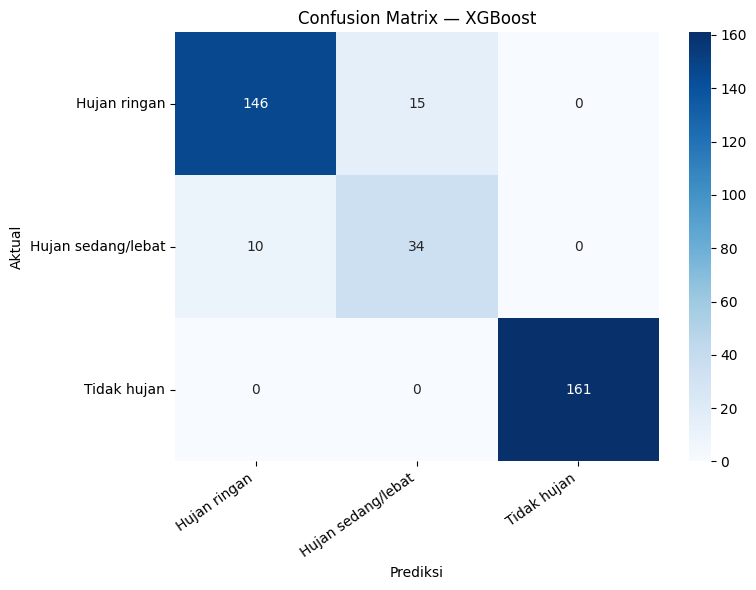

ROC curve dilewati karena target bukan biner atau data uji tidak memiliki kedua kelas.


In [8]:
y_pred = model.predict(X_test).astype(int)
y_proba = model.predict_proba(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "F1-Score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "F1-Score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
}

roc_data = None
if len(class_names) == 2 and len(np.unique(y_test)) == 2:
    try:
        roc_auc = roc_auc_score(y_test, y_proba[:, 1])
        metrics["ROC-AUC"] = roc_auc
        fpr, tpr, thresholds = roc_curve(y_test, y_proba[:, 1])
        roc_data = {"fpr": fpr.tolist(), "tpr": tpr.tolist(), "thresholds": thresholds.tolist(), "auc": float(roc_auc)}
    except ValueError:
        metrics["ROC-AUC"] = np.nan
else:
    metrics["ROC-AUC"] = np.nan

print("===== METRIK EVALUASI =====")
display(pd.DataFrame({"Metrik": list(metrics.keys()), "Nilai": [round(float(v), 4) if pd.notna(v) else np.nan for v in metrics.values()]}))

print("\\n===== CLASSIFICATION REPORT =====")
report_dict = classification_report(
    y_test, y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
display(pd.DataFrame(report_dict).T.round(3))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix — XGBoost")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

if roc_data is not None:
    plt.figure(figsize=(6, 5))
    plt.plot(roc_data["fpr"], roc_data["tpr"], label=f"ROC-AUC = {roc_data['auc']:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve — Klasifikasi Biner")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("ROC curve dilewati karena target bukan biner atau data uji tidak memiliki kedua kelas.")

,Feature,Importance
0,num__weather_code,0.807915
1,num__sunshine_duration,0.070706
2,num__temperature_2m_mean,0.025099
3,num__temperature_2m_max,0.023029
4,num__temperature_2m_min,0.020135
5,num__wind_direction_10m_dominant,0.018851
6,num__wind_gusts_10m_max,0.017231
7,num__wind_speed_10m_max,0.017034


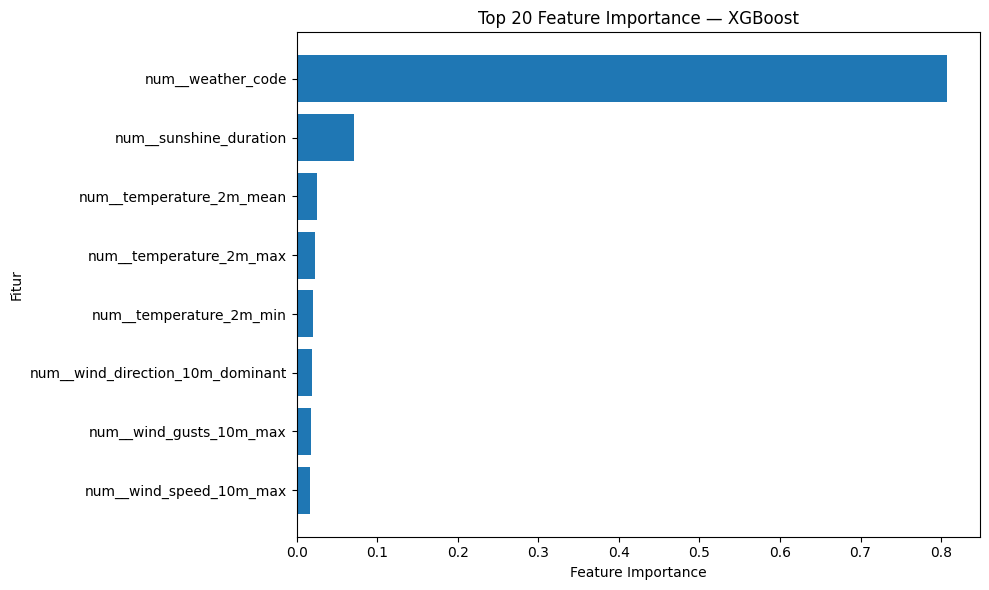

In [9]:
fitted_preprocessor = model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(feature_importance_df.head(20))

plt.figure(figsize=(10, 6))
plot_fi = feature_importance_df.head(20).sort_values("Importance", ascending=True)
plt.barh(plot_fi["Feature"], plot_fi["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.title("Top 20 Feature Importance — XGBoost")
plt.tight_layout()
plt.show()

In [10]:
import joblib
from pathlib import Path

# Data bersih untuk komponen EDA di dashboard.
dashboard_data = X.copy()
dashboard_data["__target__"] = y.astype(str)
dashboard_data.to_csv("weather_dashboard_data.csv", index=False)

# Opsi input kategori untuk form prediksi Streamlit.
categorical_options = {}
for col in categorical_cols:
    categorical_options[col] = sorted(X_train[col].dropna().astype(str).unique().tolist())

numeric_defaults = {}
for col in numeric_cols:
    median_value = pd.to_numeric(X_train[col], errors="coerce").median()
    numeric_defaults[col] = 0.0 if pd.isna(median_value) else float(median_value)

bundle = {
    "model": model,
    "label_encoder": label_encoder,
    "feature_columns": X.columns.tolist(),
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "categorical_options": categorical_options,
    "numeric_defaults": numeric_defaults,
    "class_names": class_names,
    "metrics": {key: (float(value) if pd.notna(value) else np.nan) for key, value in metrics.items()},
    "confusion_matrix": cm,
    "roc_data": roc_data,
    "classification_report": report_dict,
    "feature_importance_df": feature_importance_df,
    "target_name": TARGET_NAME,
    "target_source": TARGET_SOURCE,
    "target_is_derived": TARGET_IS_DERIVED,
    "split_strategy": split_strategy,
}
joblib.dump(bundle, "weather_xgb_bundle.joblib")

print("Artefak tersimpan:")
for path in ["weather_xgb_bundle.joblib", "weather_dashboard_data.csv"]:
    print("-", path, f"({Path(path).stat().st_size / 1024:.1f} KB)")

Artefak tersimpan:
- weather_xgb_bundle.joblib (384.7 KB)
- weather_dashboard_data.csv (94.7 KB)


In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

st.set_page_config(page_title="Kolkata Weather | XGBoost", page_icon="🌦️", layout="wide")

BUNDLE_PATH = Path("weather_xgb_bundle.joblib")
DATA_PATH = Path("weather_dashboard_data.csv")

st.title("Kolkata Climate & Weather — XGBoost Classifier")
st.caption("Dashboard klasifikasi cuaca berdasarkan dataset harian Kolkata (2021–2025).")
st.caption(f"Target klasifikasi: {joblib.load(BUNDLE_PATH)['target_name'] if BUNDLE_PATH.exists() else 'belum tersedia'}")

if not BUNDLE_PATH.exists() or not DATA_PATH.exists():
    st.error("File model atau data dashboard belum ditemukan. Jalankan notebook Colab sampai bagian Simpan Artefak terlebih dahulu.")
    st.stop()

bundle = joblib.load(BUNDLE_PATH)
data = pd.read_csv(DATA_PATH)
model = bundle["model"]
label_encoder = bundle["label_encoder"]
feature_columns = bundle["feature_columns"]
numeric_cols = bundle["numeric_cols"]
categorical_cols = bundle["categorical_cols"]
class_names = bundle["class_names"]
metrics = bundle["metrics"]

# Tabs dashboard
TabRingkasan, TabEDA, TabEvaluasi, TabImportance, TabPrediksi = st.tabs([
    "Ringkasan", "Eksplorasi Data", "Evaluasi Model", "Feature Importance", "Prediksi Manual"
])

with TabRingkasan:
    st.subheader("Ringkasan Dataset dan Model")
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Jumlah data", f"{len(data):,}")
    m2.metric("Jumlah fitur", f"{len(feature_columns):,}")
    m3.metric("Jumlah kelas", f"{len(class_names):,}")
    m4.metric("Accuracy", f"{metrics.get('Accuracy', float('nan')):.3f}")

    left, right = st.columns([1, 1])
    with left:
        st.markdown("**Proporsi kelas target**")
        target_counts = data["__target__"].astype(str).value_counts().rename_axis("Kelas").to_frame("Jumlah")
        st.bar_chart(target_counts)
    with right:
        st.markdown("**Metrik evaluasi pada data uji**")
        metrics_df = pd.DataFrame({"Metrik": list(metrics.keys()), "Nilai": list(metrics.values())})
        metrics_df["Nilai"] = metrics_df["Nilai"].apply(lambda x: round(float(x), 4) if pd.notna(x) else np.nan)
        st.dataframe(metrics_df, hide_index=True, use_container_width=True)

    st.info(
        "Catatan: target dan fitur ditentukan otomatis dari struktur CSV. Periksa kembali kolom target dan "
        "makna fitur sebelum menggunakan hasil untuk kesimpulan penelitian."
    )

with TabEDA:
    st.subheader("Eksplorasi Data (EDA)")
    numeric_available = [c for c in numeric_cols if c in data.columns]
    if numeric_available:
        chosen_feature = st.selectbox("Pilih fitur numerik untuk melihat distribusi", numeric_available)
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.histplot(data[chosen_feature].dropna(), bins=25, kde=True, ax=ax)
        ax.set_title(f"Distribusi {chosen_feature}")
        ax.set_xlabel(chosen_feature)
        ax.set_ylabel("Frekuensi")
        st.pyplot(fig)
        plt.close(fig)

        if len(numeric_available) >= 2:
            st.markdown("**Korelasi antarfitur numerik**")
            corr_cols = numeric_available[:20]
            corr = data[corr_cols].corr(numeric_only=True)
            fig, ax = plt.subplots(figsize=(10, 6))
            sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
            ax.set_title("Heatmap Korelasi")
            st.pyplot(fig)
            plt.close(fig)
    else:
        st.warning("Tidak ditemukan fitur numerik untuk divisualisasikan.")

    st.markdown("**Distribusi kelas target**")
    counts = data["__target__"].astype(str).value_counts()
    st.bar_chart(counts)

with TabEvaluasi:
    st.subheader("Evaluasi Model")
    cm = np.asarray(bundle["confusion_matrix"])
    classes = list(bundle["class_names"])
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_title("Confusion Matrix")
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    st.pyplot(fig)
    plt.close(fig)

    roc_info = bundle.get("roc_data")
    if roc_info:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(roc_info["fpr"], roc_info["tpr"], label=f"AUC = {roc_info['auc']:.3f}")
        ax.plot([0, 1], [0, 1], linestyle="--")
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title("ROC Curve")
        ax.legend(loc="lower right")
        st.pyplot(fig)
        plt.close(fig)
    else:
        st.caption("ROC curve tidak ditampilkan karena target bukan klasifikasi biner atau data uji tidak memiliki kedua kelas.")

    report = bundle.get("classification_report")
    if report:
        st.markdown("**Classification report**")
        st.dataframe(pd.DataFrame(report).T.round(3), use_container_width=True)

with TabImportance:
    st.subheader("Feature Importance")
    fi = bundle.get("feature_importance_df")
    if isinstance(fi, pd.DataFrame) and not fi.empty:
        fi = fi.sort_values("Importance", ascending=True).tail(20)
        st.bar_chart(fi.set_index("Feature")["Importance"])
        st.dataframe(fi.sort_values("Importance", ascending=False), hide_index=True, use_container_width=True)
    else:
        st.warning("Feature importance tidak tersedia.")

with TabPrediksi:
    st.subheader("Coba Prediksi dengan Input Manual")
    st.write("Masukkan nilai fitur. Nilai default numerik menggunakan median data latih; kategori mengikuti data latih.")
    input_values = {}
    with st.form("manual_prediction_form"):
        columns_layout = st.columns(2)
        for i, feature in enumerate(feature_columns):
            container = columns_layout[i % 2]
            with container:
                if feature in numeric_cols:
                    default_value = bundle["numeric_defaults"].get(feature, 0.0)
                    try:
                        default_value = float(default_value)
                    except (TypeError, ValueError):
                        default_value = 0.0
                    if not np.isfinite(default_value):
                        default_value = 0.0
                    input_values[feature] = st.number_input(feature, value=default_value, key=f"num_{i}")
                else:
                    options = bundle["categorical_options"].get(feature, [])
                    options = [str(v) for v in options if pd.notna(v)]
                    options = list(dict.fromkeys(options))
                    if options:
                        input_values[feature] = st.selectbox(feature, options=options, key=f"cat_{i}")
                    else:
                        input_values[feature] = st.text_input(feature, value="", key=f"txt_{i}")
        submitted = st.form_submit_button("Prediksi Kelas")

    if submitted:
        input_frame = pd.DataFrame([input_values], columns=feature_columns)
        prediction_encoded = int(model.predict(input_frame)[0])
        prediction_label = label_encoder.inverse_transform([prediction_encoded])[0]
        st.success(f"Prediksi kelas: **{prediction_label}**")
        try:
            probabilities = model.predict_proba(input_frame)[0]
            probability_df = pd.DataFrame({"Kelas": class_names, "Probabilitas": probabilities})
            probability_df = probability_df.sort_values("Probabilitas", ascending=False)
            st.markdown("**Probabilitas prediksi**")
            st.dataframe(probability_df.assign(Probabilitas=probability_df["Probabilitas"].map(lambda x: f"{x:.2%}")), hide_index=True, use_container_width=True)
        except Exception as exc:
            st.caption(f"Probabilitas tidak dapat ditampilkan: {exc}")


Writing app.py


In [12]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &
!sleep 3
!cat streamlit.log

In [13]:
# Alternatif LocalTunnel: buat tautan publik sementara dengan Cloudflare Tunnel.
# Jalankan setelah server Streamlit di port 8501 aktif. Cell ini akan tetap berjalan selama tunnel dipakai.
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!./cloudflared tunnel --url http://127.0.0.1:8501

2026-10-25T06:20:08Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-25T06:20:08Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-25T06:20:11Z INF +--------------------------------------------------------------------------------------------+
2026-10-25T06:20:11Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-25T06:20:11Z INF |  https://exists-foundation-colin-staff.trycloudflare.c